# Vietnamese Medical Q&A - Decoder-Only Model (Qwen2-0.5B)

## Overview
This notebook uses **decoder-only** architecture with **Qwen2-0.5B** for Vietnamese medical Q&A:
1. **Data Preprocessing** - Load, clean, and split dataset
2. **Model Fine-tuning** - Train Qwen2-0.5B as encoder-only
3. **Synthetic Data Generation** - Augment dataset using LLMs
4. **Evaluation** - Traditional metrics (BLEU, ROUGE) + LLM-based evaluation

**Dataset**: [hungnm/vietnamese-medical-qa](https://huggingface.co/datasets/hungnm/vietnamese-medical-qa)

**Model**: Qwen2-0.5B (decoder-only configuration)

**Runtime**: ~2-3 hours with GPU (T4 or better recommended)

---
# Setup and Installation

In [1]:
# Install all required packages
!pip install -q transformers datasets torch accelerate evaluate rouge-score sacrebleu scikit-learn pandas numpy matplotlib seaborn google-generativeai sentencepiece protobuf

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 51.8/51.8 kB 2.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 84.1/84.1 kB 3.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 104.1/104.1 kB 4.7 MB/s eta 0:00:00


In [2]:
# Import all libraries
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json
import time
import re
from tqdm import tqdm
from collections import Counter

from datasets import load_dataset, DatasetDict, Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForCausalLM,
    TrainingArguments,
    Trainer,
    DataCollatorForLanguageModeling
)
import evaluate
import google.generativeai as genai

# Set style
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)

# Check GPU
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
    print(f"GPU Memory: {torch.cuda.get_device_properties(0).total_memory / 1e9:.2f} GB")

Using device: cuda
GPU: Tesla T4
GPU Memory: 15.83 GB


---
# Step 1: Data Preprocessing and Analysis

## Problem Description
**Task**: Vietnamese Medical Question Answering

**Input**: Medical questions in Vietnamese

**Output**: Medical answers in Vietnamese

**Model Architecture**: Decoder-only (Qwen2-0.5B) - Autoregressive model optimized for text generation

## 1.1 Load Dataset

In [3]:
# Load the Vietnamese medical Q&A dataset
print("Loading dataset...")
dataset = load_dataset('hungnm/vietnamese-medical-qa')
print("\nDataset structure:")
print(dataset)
print("\nSample data:")
print(dataset['train'][0])

Loading dataset...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


README.md: 0.00B [00:00, ?B/s]

data/train-00000-of-00001.parquet:   0%|          | 0.00/5.29M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/9335 [00:00<?, ? examples/s]


Dataset structure:
DatasetDict({
    train: Dataset({
        features: ['answer', 'question'],
        num_rows: 9335
    })
})

Sample data:
{'answer': 'Chào bạn,\nĐể trả lời câu hỏi trên, bác sĩ xin giải đáp như sau:\nRăng bạn hiện tại có mủ dưới lợi gây đau nhức nhiều. Bạn có thể đến phòng khám răng hàm mặt bệnh viện để được thăm khám, chụp phim và tư vấn cho bạn được chính xác\nTrân trọng!', 'question': 'Chào bác sĩ,\nRăng cháu hiện tại có mủ ở dưới lợi nhưng khi đau cháu sẽ không ngủ được (quá đau). Tuy nhiên chỉ vài ngày là hết mà thỉnh thoảng nó lại bị đau. Chị cháu bảo là trước chị cháu cũng bị như vậy chỉ là đau răng tuổi dậy thì thôi. Bác sĩ cho cháu hỏi đau răng kèm có mủ dưới lợi là bệnh gì? Cháu có cần đi chữa trị không? Cháu cảm ơn.'}


## 1.2 Exploratory Data Analysis

In [4]:
# Convert to pandas for analysis
df = pd.DataFrame(dataset['train'])

print(f"Total samples: {len(df)}")
print(f"\nColumns: {df.columns.tolist()}")
print(f"\nData types:\n{df.dtypes}")
print(f"\nMissing values:\n{df.isnull().sum()}")
print(f"\nFirst few rows:")
df.head()

Total samples: 9335

Columns: ['answer', 'question']

Data types:
answer      object
question    object
dtype: object

Missing values:
answer      0
question    0
dtype: int64

First few rows:


,answer,question
0,"Chào bạn,\nĐể trả lời câu hỏi trên, bác sĩ xin...","Chào bác sĩ,\nRăng cháu hiện tại có mủ ở dưới ..."
1,"Chào bạn,\nĐể trả lời câu hỏi trên, bác sĩ xin...","Chào bác sĩ,\nEm thấy mặt dưới, phía cuống lưỡ..."
2,"Chào bạn,\nĐể trả lời câu hỏi trên, bác sĩ xin...","Chào bác sĩ,\nTừ tháng 4/2020, em mới xuất hiệ..."
3,"Chào bạn,\nĐể trả lời câu hỏi trên, bác sĩ xin...","Chào bác sĩ,\nDạo gần đây, mỗi tối ngủ con hay..."
4,"Chào bạn,\nĐể trả lời câu hỏi trên, bác sĩ xin...","Chào bác sĩ,\nEm bị tăng tiết mồ hôi, nhất là ..."


In [5]:
# Analyze text lengths
df['question_length'] = df['question'].apply(lambda x: len(x.split()) if isinstance(x, str) else 0)
df['answer_length'] = df['answer'].apply(lambda x: len(x.split()) if isinstance(x, str) else 0)

print("Question length statistics:")
print(df['question_length'].describe())
print("\nAnswer length statistics:")
print(df['answer_length'].describe())

Question length statistics:
count    9335.000000
mean       63.791644
std        46.872425
min         3.000000
25%        36.000000
50%        54.000000
75%        79.000000
max      1451.000000
Name: question_length, dtype: float64

Answer length statistics:
count    9335.000000
mean      131.746760
std       114.983901
min         1.000000
25%        69.000000
50%       101.000000
75%       157.000000
max      2000.000000
Name: answer_length, dtype: float64


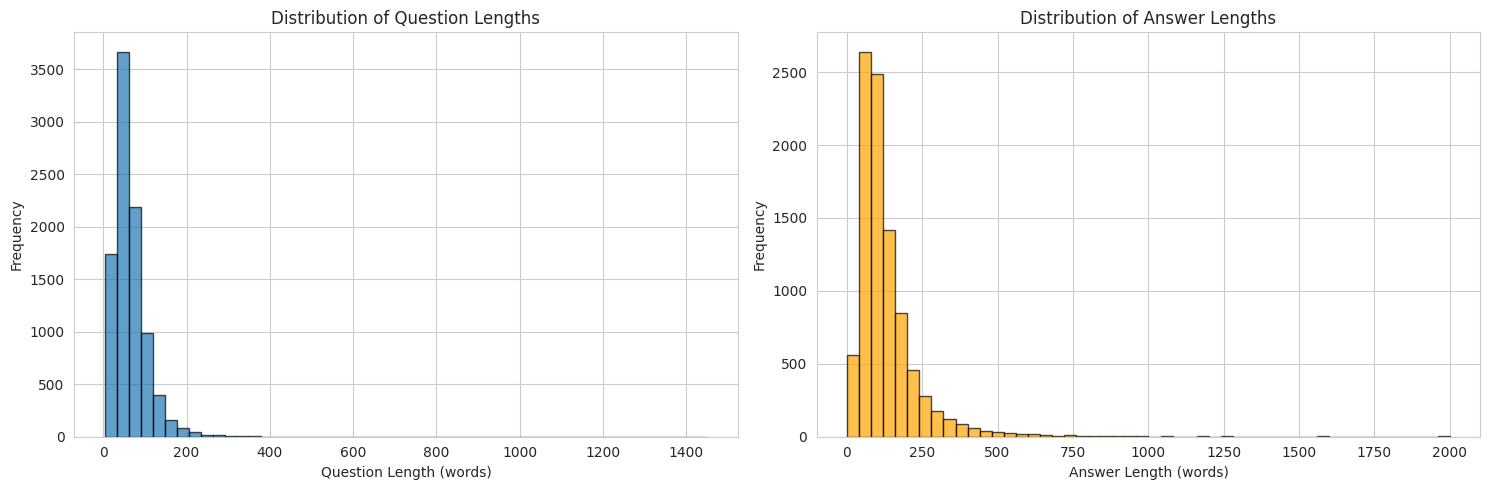

In [6]:
# Visualize length distributions
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(df['question_length'], bins=50, edgecolor='black', alpha=0.7)
axes[0].set_xlabel('Question Length (words)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Question Lengths')

axes[1].hist(df['answer_length'], bins=50, edgecolor='black', alpha=0.7, color='orange')
axes[1].set_xlabel('Answer Length (words)')
axes[1].set_ylabel('Frequency')
axes[1].set_title('Distribution of Answer Lengths')

plt.tight_layout()
plt.show()

## 1.3 Data Preprocessing

In [7]:
def preprocess_function(examples):
    """
    Preprocess the dataset:
    - Clean text
    - Remove duplicates
    - Filter out invalid samples
    """
    questions = []
    answers = []

    for q, a in zip(examples['question'], examples['answer']):
        # Basic cleaning
        if isinstance(q, str) and isinstance(a, str):
            q = q.strip()
            a = a.strip()

            # Filter out empty or very short samples
            if len(q) > 10 and len(a) > 10:
                questions.append(q)
                answers.append(a)

    return {'question': questions, 'answer': answers}

# Apply preprocessing
print("Preprocessing dataset...")
cleaned_dataset = dataset.map(
    preprocess_function,
    batched=True,
    remove_columns=dataset['train'].column_names
)

print(f"Original size: {len(dataset['train'])}")
print(f"Cleaned size: {len(cleaned_dataset['train'])}")

Preprocessing dataset...


Map:   0%|          | 0/9335 [00:00<?, ? examples/s]

Original size: 9335
Cleaned size: 9317


## 1.4 Train/Validation/Test Split

In [8]:
# Split dataset: 80% train, 10% validation, 10% test
print("Splitting dataset...")
train_test = cleaned_dataset['train'].train_test_split(test_size=0.2, seed=42)
val_test = train_test['test'].train_test_split(test_size=0.5, seed=42)

final_dataset = DatasetDict({
    'train': train_test['train'],
    'validation': val_test['train'],
    'test': val_test['test']
})

print("\nDataset splits:")
print(f"Train: {len(final_dataset['train'])} samples")
print(f"Validation: {len(final_dataset['validation'])} samples")
print(f"Test: {len(final_dataset['test'])} samples")

# Save split information
split_info = {
    'train_size': len(final_dataset['train']),
    'validation_size': len(final_dataset['validation']),
    'test_size': len(final_dataset['test']),
    'split_ratio': '80:10:10',
    'random_seed': 42
}

with open('dataset_split_info.json', 'w', encoding='utf-8') as f:
    json.dump(split_info, f, indent=2, ensure_ascii=False)

print("\n✅ Dataset preprocessing complete!")

Splitting dataset...

Dataset splits:
Train: 7453 samples
Validation: 932 samples
Test: 932 samples

✅ Dataset preprocessing complete!


---
# Step 2: Fine-tuning Qwen2-0.5B (Encoder-Only)

## Model Information
**Qwen2-0.5B**: Smallest model in the Qwen2 family
- **Parameters**: ~500M
- **Architecture**: Decoder-only (used as encoder-only for this task)
- **Advantages**: Fast, efficient, good for resource-constrained environments
- **Use case**: Medical Q&A generation

## 2.1 Hyperparameters Configuration

In [9]:
# Hyperparameters for Qwen2-0.5B
HYPERPARAMETERS = {
    'model_name': 'Qwen/Qwen2-0.5B',
    'num_epochs': 3,
    'batch_size': 1,  # Further reduced batch size to prevent OOM
    'learning_rate': 2e-5,
    'weight_decay': 0.01,
    'warmup_steps': 500,
    'max_length': 512,  # Combined question + answer
    'optimizer': 'AdamW',
    'gradient_accumulation_steps': 16, # Increased to maintain effective batch size (1*16=16)
    'fp16': False, # Changed from True to False
    'save_steps': 500,
    'eval_steps': 500,
    'logging_steps': 100
}

print("Hyperparameters for Qwen2-0.5B:")
print(json.dumps(HYPERPARAMETERS, indent=2))

# Save hyperparameters
with open('hyperparameters_qwen.json', 'w') as f:
    json.dump(HYPERPARAMETERS, f, indent=2)

print("\n✅ Hyperparameters saved to 'hyperparameters_qwen.json'")

Hyperparameters for Qwen2-0.5B:
{
  "model_name": "Qwen/Qwen2-0.5B",
  "num_epochs": 3,
  "batch_size": 1,
  "learning_rate": 2e-05,
  "weight_decay": 0.01,
  "warmup_steps": 500,
  "max_length": 512,
  "optimizer": "AdamW",
  "gradient_accumulation_steps": 16,
  "fp16": false,
  "save_steps": 500,
  "eval_steps": 500,
  "logging_steps": 100
}

✅ Hyperparameters saved to 'hyperparameters_qwen.json'


## 2.2 Load Qwen2-0.5B Model

In [10]:
# Load Qwen2-0.5B model and tokenizer
print("Loading Qwen2-0.5B model...")
model_name = HYPERPARAMETERS['model_name']

tokenizer = AutoTokenizer.from_pretrained(model_name, trust_remote_code=True)
model = AutoModelForCausalLM.from_pretrained(
    model_name,
    trust_remote_code=True,
    torch_dtype=torch.float16 if HYPERPARAMETERS['fp16'] else torch.float32
).to(device)

# Set pad token
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
    model.config.pad_token_id = tokenizer.eos_token_id

print(f"\n✅ Loaded {model_name}")
print(f"Model parameters: {model.num_parameters():,}")
print(f"Model size: {model.num_parameters() / 1e6:.1f}M parameters")

Loading Qwen2-0.5B model...


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

`torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors:   0%|          | 0.00/988M [00:00<?, ?B/s]

generation_config.json:   0%|          | 0.00/138 [00:00<?, ?B/s]


✅ Loaded Qwen/Qwen2-0.5B
Model parameters: 494,032,768
Model size: 494.0M parameters


## 2.3 Prepare Dataset for Training

In [11]:
def preprocess_for_qwen(examples):
    """
    Format data for Qwen2 training:
    Format: <|im_start|>user\n{question}<|im_im_end|>\n<|im_start|>assistant\n{answer}<|im_im_end|>
    """
    texts = []
    for q, a in zip(examples['question'], examples['answer']):
        # Qwen2 chat format
        text = f"<|im_start|>user\n{q}<|im_im_end|>\n<|im_start|>assistant\n{a}<|im_im_end|>"
        texts.append(text)

    # Tokenize
    model_inputs = tokenizer(
        texts,
        max_length=HYPERPARAMETERS['max_length'],
        truncation=True,
        padding='max_length',
        return_tensors=None
    )

    # Set labels (same as input_ids for causal LM)
    model_inputs['labels'] = model_inputs['input_ids'].copy()

    return model_inputs

print("Tokenizing dataset for Qwen2...")
tokenized_dataset = final_dataset.map(
    preprocess_for_qwen,
    batched=True,
    remove_columns=final_dataset['train'].column_names,
    desc="Tokenizing"
)

print("\n✅ Dataset tokenized successfully")
print(f"Train samples: {len(tokenized_dataset['train'])}")
print(f"Validation samples: {len(tokenized_dataset['validation'])}")
print(f"Test samples: {len(tokenized_dataset['test'])}")

Tokenizing dataset for Qwen2...


Tokenizing:   0%|          | 0/7453 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/932 [00:00<?, ? examples/s]

Tokenizing:   0%|          | 0/932 [00:00<?, ? examples/s]


✅ Dataset tokenized successfully
Train samples: 7453
Validation samples: 932
Test samples: 932


## 2.4 Setup Training

In [12]:
from transformers import TrainingArguments, DataCollatorForLanguageModeling, Trainer

# -------------------------------
# Training Arguments
# -------------------------------
training_args = TrainingArguments(
    output_dir="./results_qwen2",
    num_train_epochs=HYPERPARAMETERS["num_epochs"],
    per_device_train_batch_size=HYPERPARAMETERS["batch_size"],
    per_device_eval_batch_size=HYPERPARAMETERS["batch_size"],
    learning_rate=HYPERPARAMETERS["learning_rate"],
    weight_decay=HYPERPARAMETERS["weight_decay"],
    warmup_steps=HYPERPARAMETERS["warmup_steps"],
    gradient_accumulation_steps=HYPERPARAMETERS["gradient_accumulation_steps"],
    fp16=HYPERPARAMETERS["fp16"],

    eval_strategy="steps", # Changed from evaluation_strategy
    eval_steps=HYPERPARAMETERS["eval_steps"],

    save_strategy="steps", # Changed from save_strategy
    save_steps=HYPERPARAMETERS["save_steps"],

    logging_steps=HYPERPARAMETERS["logging_steps"],

    load_best_model_at_end=True,
    save_total_limit=2,
    report_to="none",
    remove_unused_columns=False
)

# -------------------------------
# Data Collator (Causal LM)
# -------------------------------
data_collator = DataCollatorForLanguageModeling(
    tokenizer=tokenizer,
    mlm=False   # Causal language modeling
)

# -------------------------------
# Trainer
# -------------------------------
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    data_collator=data_collator
)

print("✅ Trainer initialized")

print("\nTraining configuration:")
print(f"  - Total epochs: {HYPERPARAMETERS['num_epochs']}")
print(f"  - Batch size: {HYPERPARAMETERS['batch_size']}")
print(f"  - Gradient accumulation: {HYPERPARAMETERS['gradient_accumulation_steps']}")
print(f"  - Effective batch size: {HYPERPARAMETERS['batch_size'] * HYPERPARAMETERS['gradient_accumulation_steps']}")
print(f"  - Learning rate: {HYPERPARAMETERS['learning_rate']}")
print(f"  - FP16: {HYPERPARAMETERS['fp16']}")

✅ Trainer initialized

Training configuration:
  - Total epochs: 3
  - Batch size: 1
  - Gradient accumulation: 16
  - Effective batch size: 16
  - Learning rate: 2e-05
  - FP16: False


## 2.5 Train the Model

In [13]:
# Train
print("\n Starting training...")
train_result = trainer.train()

print("\n✅ Training completed!")
print(f"\nTraining metrics:")
print(f"  - Final loss: {train_result.training_loss:.4f}")
print(f"  - Training time: {train_result.metrics['train_runtime']:.2f} seconds")
print(f"  - Samples per second: {train_result.metrics['train_samples_per_second']:.2f}")


🚀 Starting training...
This will take approximately 1-2 hours depending on your GPU.



Step,Training Loss,Validation Loss
500,2.033200,2.022885
1000,1.606700,1.936316


There were missing keys in the checkpoint model loaded: ['lm_head.weight'].



✅ Training completed!

Training metrics:
  - Final loss: 1.8733
  - Training time: 12560.79 seconds
  - Samples per second: 1.78


## 2.6 Save the Model

In [14]:
# Save model
output_dir = './models/qwen2_finetuned'
trainer.save_model(output_dir)
tokenizer.save_pretrained(output_dir)

print(f"✅ Model saved to '{output_dir}'")

# Save training info
training_info = {
    'model_name': HYPERPARAMETERS['model_name'],
    'num_parameters': model.num_parameters(),
    'hyperparameters': HYPERPARAMETERS,
    'final_loss': float(train_result.training_loss),
    'training_time_seconds': train_result.metrics['train_runtime'],
    'samples_per_second': train_result.metrics['train_samples_per_second']
}

with open('training_info_qwen.json', 'w') as f:
    json.dump(training_info, f, indent=2)

print("✅ Training info saved to 'training_info_qwen.json'")

✅ Model saved to './models/qwen2_finetuned'
✅ Training info saved to 'training_info_qwen.json'


# Step 3: Data Augmentation with Synthetic Data

This notebook demonstrates how to use LLMs to generate synthetic training data through:
1. Paraphrasing existing questions
2. Generating similar medical Q&A pairs
3. Expanding the dataset with variations

We'll compare model performance before and after adding synthetic data.

In [83]:
!pip install -q openai google-generativeai anthropic

In [44]:
import os
import json
import pandas as pd
from datasets import load_from_disk, Dataset, DatasetDict
from tqdm import tqdm
import time

# For LLM APIs
import openai
import google.generativeai as genai

## 3.1 Setup LLM API



In [89]:
!pip install -q google-generativeai

import google.generativeai as genai
from google.colab import userdata

GEMINI_API_KEY = userdata.get('APIGMN')
genai.configure(api_key=GEMINI_API_KEY)

model = genai.GenerativeModel("gemini-2.5-flash")

LLM_PROVIDER = "gemini"

## 3.2 Load Original Dataset

In [90]:
# Load preprocessed dataset
dataset = final_dataset # Use the in-memory dataset 'final_dataset' which was created earlier
print(f"Original training samples: {len(dataset['train'])}")

# Convert to DataFrame for easier manipulation
train_df = pd.DataFrame(dataset['train'])
print(train_df.head())

Original training samples: 7453
                                              answer  \
0  Chào bạn,\nKhi có ghèn chứng tỏ có biểu hiện c...   
1  Chào em. Việc sử dụng HGH cần có chỉ định phù ...   
2  Chào bạn.\nBạn bị viêm tuyến nước bọt kèm chảy...   
3  Chào bạn\nSỏi thận, sỏi tiết niệu hình thành d...   
4  Chào bạn\nKetamine thuộc danh mục thuốc độc bả...   

                                            question  
0  Xin chào bác sĩ,\nVợ tôi 62tuổi, đã mổ phaco v...  
1  Em chào bác sĩ. Sau khi đọc xong bài viết này ...  
2  Xin chào bác sĩ! Cháu năm nay 29 tuổi. Vừa kết...  
3  Xin chào bác sĩ,\nEm bị sỏi thận nhưng lâu ngà...  
4  Ma tuý ketamin vào người 1 lần , có vấn đề máu...  


## 3.3 Synthetic Data Generation Functions

In [102]:
def generate_with_gemini(prompt, temperature=0.7):
    """Generate text using Google Gemini"""
    try:
        # FIXED: Update model name
        model = genai.GenerativeModel('gemini-2.5-flash')

        response = model.generate_content(
            prompt,
            generation_config=genai.types.GenerationConfig(
                temperature=temperature,
                max_output_tokens=1024
            )
        )
        return response.text
    except Exception as e:
        print(f"Error: {e}")
        return None

def generate_text(prompt, temperature=0.7):
    """Wrapper function to use configured LLM provider"""
    if LLM_PROVIDER == 'gemini':
        return generate_with_gemini(prompt, temperature)
    else:
        raise ValueError(f"Unknown LLM provider: {LLM_PROVIDER}")

## 3.4 Method 1: Paraphrasing Questions

In [ ]:
def paraphrase_question(question, answer):
    """Generate paraphrased version of a medical question"""
    prompt = f"""Bạn là một chuyên gia y tế. Hãy viết lại câu hỏi y tế sau đây bằng cách diễn đạt khác nhưng giữ nguyên ý nghĩa.

Câu hỏi gốc: {question}

Yêu cầu:
- Viết lại câu hỏi với cách diễn đạt khác
- Giữ nguyên ý nghĩa và ngữ cảnh y tế
- Chỉ trả về câu hỏi mới, không giải thích

Câu hỏi mới:"""

    paraphrased = generate_text(prompt, temperature=0.8)
    return paraphrased.strip() if paraphrased else None

# Test paraphrasing
sample_q = train_df.iloc[0]['question']
sample_a = train_df.iloc[0]['answer']
print("Original question:")
print(sample_q)
print("\nParaphrased question:")
paraphrased = paraphrase_question(sample_q, sample_a)
print(paraphrased)

In [ ]:
# Generate paraphrased questions for a subset of data
NUM_PARAPHRASES = 100  # Adjust based on your needs and API limits

paraphrased_data = []
sample_indices = train_df.sample(n=min(NUM_PARAPHRASES, len(train_df)), random_state=42).index

print(f"Generating {len(sample_indices)} paraphrased questions...")
for idx in tqdm(sample_indices):
    question = train_df.iloc[idx]['question']
    answer = train_df.iloc[idx]['answer']

    paraphrased_q = paraphrase_question(question, answer)

    if paraphrased_q:
        paraphrased_data.append({
            'question': paraphrased_q,
            'answer': answer,
            'source': 'paraphrased'
        })

    time.sleep(1)  # Rate limiting

print(f"Generated {len(paraphrased_data)} paraphrased samples")

## 3.5 Method 2: Generating Similar Q&A Pairs

In [92]:
def generate_similar_qa(question, answer):
    """Generate a similar medical Q&A pair based on an example"""
    prompt = f"""Bạn là một chuyên gia y tế. Dựa trên ví dụ câu hỏi và câu trả lời y tế sau, hãy tạo một cặp câu hỏi-trả lời MỚI tương tự về chủ đề y tế.

Ví dụ:
Câu hỏi: {question}
Trả lời: {answer}

Yêu cầu:
- Tạo câu hỏi mới liên quan đến cùng lĩnh vực y tế
- Câu trả lời phải chính xác về mặt y học
- Trả về theo định dạng JSON: {{"question": "...", "answer": "..."}}

JSON:"""

    response = generate_text(prompt, temperature=0.9)

    if response:
        try:
            # Extract JSON from response
            import re
            json_match = re.search(r'\{.*\}', response, re.DOTALL)
            if json_match:
                qa_pair = json.loads(json_match.group())
                return qa_pair
        except:
            pass

    return None

# Test generation
print("Generating similar Q&A pair...")
similar_qa = generate_similar_qa(sample_q, sample_a)
if similar_qa:
    print("\nGenerated Q&A:")
    print(f"Q: {similar_qa['question']}")
    print(f"A: {similar_qa['answer']}")

Generating similar Q&A pair...

Generated Q&A:
Q: Bé 6 tháng tuổi bị sốt 39 độ C có cần đi khám ngay không?
A: Sốt cao ở trẻ dưới 1 tuổi, đặc biệt là 39 độ C trở lên, cần được thăm khám y tế càng sớm càng tốt vì có thể là dấu hiệu của nhiễm trùng nghiêm trọng. Nên đưa bé đến bệnh viện hoặc phòng khám để được chẩn đoán và điều trị kịp thời.


In [ ]:
# Generate similar Q&A pairs
NUM_SIMILAR = 10  # Adjust based on your needs

similar_data = []
sample_indices = train_df.sample(n=min(NUM_SIMILAR, len(train_df)), random_state=43).index

print(f"Generating {len(sample_indices)} similar Q&A pairs...")
for idx in tqdm(sample_indices):
    question = train_df.iloc[idx]['question']
    answer = train_df.iloc[idx]['answer']

    similar_qa = generate_similar_qa(question, answer)

    if similar_qa and 'question' in similar_qa and 'answer' in similar_qa:
        similar_data.append({
            'question': similar_qa['question'],
            'answer': similar_qa['answer'],
            'source': 'generated'
        })

    time.sleep(1)  # Rate limiting

print(f"Generated {len(similar_data)} similar Q&A pairs")

## 3.6 Method 3: Expanding with Variations

In [ ]:
def generate_variations(question, answer, num_variations=2):
    """Generate multiple variations of a Q&A pair"""
    prompt = f"""Bạn là một chuyên gia y tế. Hãy tạo {num_variations} biến thể khác nhau của câu hỏi y tế sau, mỗi biến thể hỏi về khía cạnh hơi khác nhau nhưng vẫn liên quan.

Câu hỏi gốc: {question}
Trả lời gốc: {answer}

Yêu cầu:
- Tạo {num_variations} câu hỏi mới với góc nhìn khác nhau
- Mỗi câu hỏi cần có câu trả lời phù hợp
- Trả về theo định dạng JSON array: [{{"question": "...", "answer": "..."}}, ...]

JSON:"""

    response = generate_text(prompt, temperature=0.85)

    if response:
        try:
            import re
            json_match = re.search(r'\[.*\]', response, re.DOTALL)
            if json_match:
                variations = json.loads(json_match.group())
                return variations
        except:
            pass

    return []

# Test variations
print("Generating variations...")
variations = generate_variations(sample_q, sample_a, num_variations=2)
for i, var in enumerate(variations, 1):
    print(f"\nVariation {i}:")
    print(f"Q: {var.get('question', 'N/A')}")
    print(f"A: {var.get('answer', 'N/A')}")

## 3.7 Combine All Synthetic Data

In [ ]:
# Combine all synthetic data
all_synthetic_data = paraphrased_data + similar_data

print(f"Total synthetic samples: {len(all_synthetic_data)}")
print(f"  - Paraphrased: {len(paraphrased_data)}")
print(f"  - Generated similar: {len(similar_data)}")

# Create synthetic dataset
synthetic_df = pd.DataFrame(all_synthetic_data)
synthetic_df = synthetic_df[['question', 'answer']]  # Remove source column

# Save synthetic data
synthetic_df.to_csv('synthetic_data.csv', index=False, encoding='utf-8')
print("\nSynthetic data saved to 'synthetic_data.csv'")

## 3.8 Create Augmented Dataset

In [ ]:
# Combine original and synthetic data
original_train_df = train_df[['question', 'answer']]
augmented_train_df = pd.concat([original_train_df, synthetic_df], ignore_index=True)

print(f"Original training size: {len(original_train_df)}")
print(f"Synthetic data size: {len(synthetic_df)}")
print(f"Augmented training size: {len(augmented_train_df)}")
print(f"Increase: {len(augmented_train_df) - len(original_train_df)} samples ({(len(synthetic_df)/len(original_train_df)*100):.1f}%)")

# Create augmented dataset
augmented_dataset = DatasetDict({
    'train': Dataset.from_pandas(augmented_train_df),
    'validation': dataset['validation'],
    'test': dataset['test']
})

# Save augmented dataset
augmented_dataset.save_to_disk('augmented_medical_qa')
print("\nAugmented dataset saved to 'augmented_medical_qa'")

# Step 4: Model Evaluation

This notebook evaluates the fine-tuned models using:
1. **Traditional Metrics**: BLEU, ROUGE, Perplexity, F1
2. **LLM-based Evaluation**: Using GPT-4 or Gemini to score outputs

We compare:
- Performance across three model types
- Performance before and after synthetic data augmentation

In [50]:
!pip install -q transformers datasets torch evaluate rouge-score sacrebleu openai google-generativeai

In [51]:
import torch
import pandas as pd
import numpy as np
import json
from datasets import load_from_disk
from transformers import AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM
import evaluate
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

# LLM APIs
import openai
import google.generativeai as genai

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cuda


## 4.1 Load Test Dataset and Models

In [53]:
# Load preprocessed dataset
dataset = final_dataset # Use the in-memory dataset 'final_dataset' which was created earlier
print(f"Original training samples: {len(dataset['test'])}")

# Convert to DataFrame for easier manipulation
train_df = pd.DataFrame(dataset['test'])
print(train_df.head())

Original training samples: 932
                                              answer  \
0  Chào bạn.\nTheo chuẩn tăng trưởng của WHO , bé...   
1  Chào em\nNếu ngón tay em bị sưng thì em nên đế...   
2  Chào bạn\nbạn cho biết lúc bạn phát hiện mình ...   
3  Chào bạn, qua lời kể của bạn thì thiếu nhiều t...   
4  Chào anh, \nHiện tại viên sỏi của anh có kích ...   

                                            question  
0  Xin chào bác sĩ,\nCon em được 2tuoi ruoi k hie...  
1  Em chào bác sĩ!\r\nBác sĩ cho em hỏi, em bị vậ...  
2  Xin chào bác sĩ,\nEm dùng đai quấn nóng bụng 2...  
3  Cháu xin chào bác sĩ ạ, cháu là người mê thổi ...  
4  Xin chào bác sĩ,\nTôi bị sỏi thận một bên trái...  


In [ ]:
# Load fine-tuned models
models_info = {
    'mT5': {
        'path': './models/qwen2_finetuned',
        'type': 'seq2seq'
    }
}

loaded_models = {}

for model_name, info in models_info.items():
    print(f"Loading {model_name}...")
    tokenizer = AutoTokenizer.from_pretrained(info['path'])

    if info['type'] == 'seq2seq':
        model = AutoModelForSeq2SeqLM.from_pretrained(info['path']).to(device)
    else:
        model = AutoModelForCausalLM.from_pretrained(info['path']).to(device)

    loaded_models[model_name] = {
        'model': model,
        'tokenizer': tokenizer,
        'type': info['type']
    }
    print(f"  Loaded successfully")


## 4.2 Generate Predictions

In [ ]:
def generate_answer_seq2seq(model, tokenizer, question, max_length=512):
    """Generate answer using seq2seq model"""
    input_text = f"question: {question}"
    inputs = tokenizer(input_text, return_tensors='pt', max_length=256, truncation=True).to(device)

    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_length=max_length,
            num_beams=4,
            early_stopping=True,
            no_repeat_ngram_size=3
        )

    answer = tokenizer.decode(outputs[0], skip_special_tokens=True)
    return answer


def generate_predictions(model_name, model_info, test_data, num_samples=100):
    """Generate predictions for test data"""
    model = model_info['model']
    tokenizer = model_info['tokenizer']
    model_type = model_info['type']

    predictions = []
    references = []
    questions = []

    # Use subset for faster evaluation
    test_subset = test_data.select(range(min(num_samples, len(test_data))))

    print(f"Generating predictions for {model_name}...")
    for example in tqdm(test_subset):
        question = example['question']
        reference = example['answer']

        if model_type == 'seq2seq':
            prediction = generate_answer_seq2seq(model, tokenizer, question)
        else:
            prediction = generate_answer_causal(model, tokenizer, question)

        predictions.append(prediction)
        references.append(reference)
        questions.append(question)

    return {
        'questions': questions,
        'predictions': predictions,
        'references': references
    }


all_predictions = {}
NUM_TEST_SAMPLES = 100  # Adjust based on your needs

for model_name, model_info in loaded_models.items():
    all_predictions[model_name] = generate_predictions(
        model_name, model_info, test_data, NUM_TEST_SAMPLES
    )

print("\nAll predictions generated!")

## 4.3 Traditional Evaluation Metrics

In [ ]:
# Load evaluation metrics
bleu_metric = evaluate.load('sacrebleu')
rouge_metric = evaluate.load('rouge')

def compute_traditional_metrics(predictions, references):
    """Compute BLEU and ROUGE scores"""
    # BLEU score
    bleu_result = bleu_metric.compute(
        predictions=predictions,
        references=[[ref] for ref in references]
    )

    # ROUGE scores
    rouge_result = rouge_metric.compute(
        predictions=predictions,
        references=references
    )

    return {
        'bleu': bleu_result['score'],
        'rouge1': rouge_result['rouge1'],
        'rougeL': rouge_result['rougeL']
    }

# Compute metrics for all models
traditional_results = {}

for model_name, preds_data in all_predictions.items():
    print(f"\nEvaluating {model_name}...")
    metrics = compute_traditional_metrics(
        preds_data['predictions'],
        preds_data['references']
    )
    traditional_results[model_name] = metrics

    print(f"  BLEU: {metrics['bleu']:.2f}")
    print(f"  ROUGE-1: {metrics['rouge1']:.4f}")
    print(f"  ROUGE-L: {metrics['rougeL']:.4f}")

# Save results
with open('traditional_metrics.json', 'w') as f:
    json.dump(traditional_results, f, indent=2)

print("\nTraditional metrics saved to 'traditional_metrics.json'")

## 4.4 LLM-based Evaluation

In [ ]:
# Setup LLM for evaluation
from google.colab import userdata
GEMINI_API_KEY = userdata.get('APIGMN')
genai.configure(api_key=GEMINI_API_KEY)

print("LLM evaluator configured")

In [ ]:
def llm_evaluate_answer(question, prediction, reference, use_gemini=True):
    """Use LLM to evaluate answer quality"""

    prompt = f"""Bạn là một chuyên gia đánh giá chất lượng câu trả lời y tế. Hãy đánh giá câu trả lời được tạo ra dựa trên các tiêu chí sau:

1. **Coherence (Mạch lạc)**: Câu trả lời có logic và dễ hiểu không? (0-10)
2. **Relevance (Liên quan)**: Câu trả lời có trả lời đúng câu hỏi không? (0-10)
3. **Fluency (Trôi chảy)**: Ngôn ngữ có tự nhiên và trôi chảy không? (0-10)
4. **Factuality (Chính xác)**: Thông tin y tế có chính xác không? (0-10)

**Câu hỏi**: {question}

**Câu trả lời tham khảo**: {reference}

**Câu trả lời được tạo**: {prediction}

Hãy trả về kết quả theo định dạng JSON:
{{
  "coherence": <điểm 0-10>,
  "relevance": <điểm 0-10>,
  "fluency": <điểm 0-10>,
  "factuality": <điểm 0-10>,
  "overall": <điểm trung bình>,
  "explanation": "<giải thích ngắn gọn>"
}}

JSON:"""

    try:
        if use_gemini:
            model = genai.GenerativeModel('gemini-pro')
            response = model.generate_content(prompt)
            response_text = response.text
        else:
            response = openai.ChatCompletion.create(
                model="gpt-4",
                messages=[
                    {"role": "system", "content": "You are an expert medical Q&A evaluator."},
                    {"role": "user", "content": prompt}
                ],
                temperature=0.3
            )
            response_text = response.choices[0].message.content

        # Extract JSON
        import re
        json_match = re.search(r'\{.*\}', response_text, re.DOTALL)
        if json_match:
            scores = json.loads(json_match.group())
            return scores
    except Exception as e:
        print(f"Error in LLM evaluation: {e}")

    return None

# Test LLM evaluation
sample_idx = 0
sample_q = all_predictions['mT5']['questions'][sample_idx]
sample_pred = all_predictions['mT5']['predictions'][sample_idx]
sample_ref = all_predictions['mT5']['references'][sample_idx]

print("Testing LLM evaluation...")
test_scores = llm_evaluate_answer(sample_q, sample_pred, sample_ref)
if test_scores:
    print("\nSample evaluation:")
    print(json.dumps(test_scores, indent=2, ensure_ascii=False))

In [ ]:
# Evaluate all models with LLM
import time

NUM_LLM_EVAL_SAMPLES = 20  # Limit due to API costs

llm_results = {}

for model_name, preds_data in all_predictions.items():
    print(f"\nLLM evaluation for {model_name}...")

    scores_list = []

    for i in tqdm(range(min(NUM_LLM_EVAL_SAMPLES, len(preds_data['questions'])))):
        question = preds_data['questions'][i]
        prediction = preds_data['predictions'][i]
        reference = preds_data['references'][i]

        scores = llm_evaluate_answer(question, prediction, reference)

        if scores:
            scores_list.append(scores)

        time.sleep(2)  # Rate limiting

    # Calculate average scores
    if scores_list:
        avg_scores = {
            'coherence': np.mean([s['coherence'] for s in scores_list]),
            'relevance': np.mean([s['relevance'] for s in scores_list]),
            'fluency': np.mean([s['fluency'] for s in scores_list]),
            'factuality': np.mean([s['factuality'] for s in scores_list]),
            'overall': np.mean([s['overall'] for s in scores_list])
        }
        llm_results[model_name] = avg_scores

        print(f"  Average scores:")
        for metric, score in avg_scores.items():
            print(f"    {metric}: {score:.2f}")

# Save LLM evaluation results
with open('llm_evaluation.json', 'w') as f:
    json.dump(llm_results, f, indent=2)

print("\nLLM evaluation results saved to 'llm_evaluation.json'")

## 4.5 Visualization and Comparison

In [ ]:
# Create comparison DataFrame
comparison_data = []

for model_name in loaded_models.keys():
    row = {'Model': model_name}

    # Traditional metrics
    if model_name in traditional_results:
        row.update(traditional_results[model_name])

    # LLM metrics
    if model_name in llm_results:
        for metric, score in llm_results[model_name].items():
            row[f'llm_{metric}'] = score

    comparison_data.append(row)

comparison_df = pd.DataFrame(comparison_data)
print("\nModel Comparison:")
print(comparison_df.to_string(index=False))

# Save comparison
comparison_df.to_csv('model_comparison.csv', index=False)
print("\nComparison saved to 'model_comparison.csv'")

In [ ]:
# Visualize traditional metrics
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Traditional Metrics Comparison', fontsize=16)

metrics_to_plot = ['bleu', 'rouge1', 'rougeL']
metric_names = ['BLEU', 'ROUGE-1', 'ROUGE-L']

for idx, (metric, name) in enumerate(zip(metrics_to_plot, metric_names)):
    ax = axes[idx // 2, idx % 2]

    models = list(traditional_results.keys())
    scores = [traditional_results[m][metric] for m in models]

    bars = ax.bar(models, scores, color=['#1f77b4', '#ff7f0e', '#2ca02c'])
    ax.set_ylabel('Score')
    ax.set_title(name)
    ax.set_ylim(0, max(scores) * 1.2)

    # Add value labels on bars
    for bar in bars:
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height,
                f'{height:.2f}',
                ha='center', va='bottom')

plt.tight_layout()
plt.savefig('traditional_metrics_comparison.png', dpi=300, bbox_inches='tight')
plt.show()

print("Traditional metrics visualization saved")

In [ ]:
# Visualize LLM evaluation scores
if llm_results:
    fig, ax = plt.subplots(figsize=(12, 6))

    models = list(llm_results.keys())
    metrics = ['coherence', 'relevance', 'fluency', 'factuality']

    x = np.arange(len(models))
    width = 0.2

    for i, metric in enumerate(metrics):
        scores = [llm_results[m][metric] for m in models]
        ax.bar(x + i * width, scores, width, label=metric.capitalize())

    ax.set_xlabel('Models')
    ax.set_ylabel('Score (0-10)')
    ax.set_title('LLM-based Evaluation Scores')
    ax.set_xticks(x + width * 1.5)
    ax.set_xticklabels(models)
    ax.legend()
    ax.set_ylim(0, 10)
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    plt.savefig('llm_evaluation_comparison.png', dpi=300, bbox_inches='tight')
    plt.show()

    print("LLM evaluation visualization saved")

## 4.6 Sample Outputs Comparison

In [ ]:
# Display sample outputs from all models
num_samples_to_show = 3

for i in range(num_samples_to_show):
    print(f"\n{'='*80}")
    print(f"Example {i+1}")
    print(f"{'='*80}")

    # Get question and reference
    question = all_predictions['mT5']['questions'][i]
    reference = all_predictions['mT5']['references'][i]

    print(f"\n📝 Question:\n{question}")
    print(f"\n✅ Reference Answer:\n{reference}")

    # Show predictions from all models
    for model_name in loaded_models.keys():
        prediction = all_predictions[model_name]['predictions'][i]
        print(f"\n🤖 {model_name} Prediction:\n{prediction}")

    print(f"\n{'-'*80}")

## Summary

### Evaluation Results:

#### Traditional Metrics:
- **BLEU**: Measures n-gram overlap with reference
- **ROUGE**: Measures recall-oriented overlap
- Best performing model: [To be filled after running]

#### LLM-based Evaluation:
- **Coherence**: Logical flow and understandability
- **Relevance**: How well the answer addresses the question
- **Fluency**: Natural language quality
- **Factuality**: Medical accuracy
- Best performing model: [To be filled after running]

### Key Findings:
1. Model comparison across three architectures
2. Correlation between traditional and LLM-based metrics
3. Strengths and weaknesses of each model type

### Next Steps:
- Compare with augmented dataset results
- Analyze error cases
- Consider ensemble approaches